# CH20 – Air Quality Insight (EcoAir Analytics Centre)
**U23AD491 – Data Science | DS Sprint – Skill Based Assessment 2**
**Name:** PRADEEP P  |  **Reg No:** 722824104175  |  **Challenge:** CH20 – Air Quality Insight

## Round 2 – EDA and Feature Engineering
**Business question:** How do weather, location and time relate to changes in air quality?

**Notebook flow**
1. Setup
2. Create the 5 datasets (air_quality, stations, weather, traffic, calendar) with the stated data-quality problems
3. Load and inspect
4. Clean (missing values, duplicates, station names, extreme values, weather gaps)
5. Merge into one analysis table (station x hour)
6. EDA – one section per analytical question
7. Feature engineering and encoding
8. Feature selection / PCA
9. Machine-learning model (for the answer sheet)
10. Save outputs and print an answer-sheet summary

> Note: the datasets are generated synthetically in Section 2 because no raw files were provided. Mention this in your README.

## 1. Setup

In [1]:
import os, re, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

os.makedirs("data", exist_ok=True)
rng = np.random.default_rng(42)       # fixed seed -> same dataset every run

report = {}     # numbers collected for the answer sheet
findings = {}   # EDA findings collected for the answer sheet
print("Setup done")

Setup done


## 2. Dataset creation
Five CSV files are generated for **1 Jan 2024 – 31 Dec 2024, hourly, 8 stations**.
Realistic relationships are built in (low wind -> higher PM2.5, rain washes pollution, traffic peaks, winter/post-monsoon peaks, industrial stations dirtier)
and then the five data-quality problems from the question are injected on purpose.

In [2]:
# ---------- 2.1 stations.csv ----------
S = [  # name, location, land-use, base PM2.5, traffic sensitivity
    ("Gandhipuram",    "Central Zone", "Commercial",    48, 1.3),
    ("Peelamedu",      "East Zone",    "Residential",   36, 0.8),
    ("Ukkadam",        "South Zone",   "Transport Hub", 55, 1.5),
    ("Saravanampatti", "North Zone",   "Residential",   34, 0.7),
    ("Singanallur",    "East Zone",    "Industrial",    62, 0.9),
    ("RS Puram",       "Central Zone", "Commercial",    44, 1.1),
    ("Vadavalli",      "West Zone",    "Green Zone",    26, 0.5),
    ("Kuniyamuthur",   "South Zone",   "Industrial",    58, 0.9),
]
stations = pd.DataFrame([(s[0], s[1], s[2]) for s in S], columns=["station", "location", "land_use_type"])

# ---------- 2.2 calendar.csv ----------
def season_of(m):
    if m in (12, 1, 2):  return "Winter"
    if m in (3, 4, 5):   return "Summer"
    if m in (6, 7, 8, 9): return "Monsoon"
    return "Post-Monsoon"

dates = pd.date_range("2024-01-01", "2024-12-31", freq="D")
holidays = pd.to_datetime(["2024-01-01", "2024-01-15", "2024-01-26", "2024-03-29", "2024-04-14",
                           "2024-05-01", "2024-08-15", "2024-10-02", "2024-10-31", "2024-11-01", "2024-12-25"])
calendar = pd.DataFrame({
    "date": dates.strftime("%Y-%m-%d"),
    "weekday": dates.day_name(),
    "is_holiday": dates.isin(holidays).astype(int),
    "season": [season_of(m) for m in dates.month],
})

# ---------- 2.3 hourly time axis ----------
times = pd.date_range("2024-01-01 00:00", "2024-12-31 23:00", freq="h")
n = len(times)
hour = times.hour.values
doy = times.dayofyear.values
month = times.month.values
is_weekend = (times.dayofweek.values >= 5)
is_hol_h = times.normalize().isin(holidays)
season_arr = pd.Series(month).map(season_of).values

# ---------- 2.4 weather.csv ----------
temp = 28 + 3.5*np.sin(2*np.pi*(doy-60)/366) + 4*np.sin(2*np.pi*(hour-9)/24) + rng.normal(0, 0.8, n)

p_rain = pd.Series(season_arr).map({"Winter": 0.01, "Summer": 0.03, "Monsoon": 0.12, "Post-Monsoon": 0.09}).values
start = rng.random(n) < p_rain/2.5
spell = np.convolve(start.astype(int), np.ones(3), mode="same") > 0     # rain lasts a few hours
rain = np.where(spell, rng.exponential(2.0, n), 0).round(1)

humidity = (72 - 2.0*(temp-28) + np.where(rain > 0, 10, 0)
            + pd.Series(season_arr).map({"Monsoon": 10, "Post-Monsoon": 6, "Winter": 0, "Summer": -6}).values
            + rng.normal(0, 5, n))
humidity = np.clip(humidity, 25, 100).round(1)

wind_adj = pd.Series(season_arr).map({"Winter": -0.6, "Summer": 0.2, "Monsoon": 1.4, "Post-Monsoon": 0.2}).values
wind = rng.gamma(2.2, 0.9, n) + wind_adj + 0.7*np.sin(2*np.pi*(hour-9)/24)
wind = pd.Series(wind).rolling(3, min_periods=1, center=True).mean().clip(0.2, 12).round(2).values

weather = pd.DataFrame({"timestamp": times.strftime("%Y-%m-%d %H:%M:%S"),
                        "wind_speed": wind, "temperature": temp.round(1),
                        "humidity": humidity, "rain_mm": rain})

# ---------- 2.5 traffic.csv ----------
profile = np.array([0.15, 0.10, 0.08, 0.08, 0.12, 0.25, 0.50, 0.85, 1.00, 0.80, 0.65, 0.60,
                    0.62, 0.60, 0.62, 0.70, 0.85, 1.00, 0.95, 0.75, 0.55, 0.40, 0.30, 0.20])
tv = (2000*profile[hour]*np.where(is_weekend, 0.7, 1)*np.where(is_hol_h, 0.6, 1)
      * np.where(rain > 0, 0.9, 1)*(1 + rng.normal(0, 0.08, n)))
traffic_volume = np.clip(tv, 50, None).round().astype(int)
peak_flag = np.isin(hour, [7, 8, 9, 17, 18, 19]).astype(int)
traffic = pd.DataFrame({"timestamp": times.strftime("%Y-%m-%d %H:%M:%S"),
                        "traffic_volume": traffic_volume, "peak_flag": peak_flag})

# ---------- 2.6 air_quality.csv (clean version first) ----------
def sub_index(x, bp, idx=(0, 50, 100, 200, 300, 400, 500)):
    return np.interp(x, bp, idx)

season_f = pd.Series(season_arr).map({"Winter": 1.35, "Summer": 1.0, "Monsoon": 0.65, "Post-Monsoon": 1.2}).values
diurnal = 1 + 0.08*np.cos(2*np.pi*(hour-1)/24)
wind_f = np.exp(-0.18*(wind-2.5))
rain_f = np.where(rain > 0, 0.6, 1.0)
city_noise = np.exp(pd.Series(rng.normal(0, 0.6, n)).rolling(12, min_periods=1).mean().values)
diwali = ((times >= "2024-10-31 18:00") & (times <= "2024-11-01 02:00")).astype(float)*45
traffic_n = traffic_volume/2000

frames = []
for name, loc, lu, base, ts in S:
    stn_noise = np.exp(rng.normal(0, 0.10, n))
    pm25 = base*season_f*diurnal*wind_f*rain_f*city_noise*stn_noise \
           + ts*40*traffic_n*np.exp(-0.10*(wind-2.5)) + diwali*(base/48)
    pm25 = np.clip(pm25, 3, None)
    pm10 = pm25*1.6*np.exp(rng.normal(0, 0.08, n)) + (8 if lu == "Industrial" else 4)
    no2 = (10 + ts*30*traffic_n)*np.exp(-0.08*(wind-2.5))*np.where(season_arr == "Winter", 1.15, 1.0)*np.exp(rng.normal(0, 0.15, n))
    aqi = np.maximum.reduce([
        sub_index(pm25, [0, 30, 60, 90, 120, 250, 380]),
        sub_index(pm10, [0, 50, 100, 250, 350, 430, 550]),
        sub_index(no2,  [0, 40, 80, 180, 280, 400, 520]),
    ])
    frames.append(pd.DataFrame({"timestamp": times.strftime("%Y-%m-%d %H:%M:%S"), "station": name,
                                "PM2.5": pm25.round(1), "PM10": pm10.round(1),
                                "NO2": no2.round(1), "AQI": aqi.round().astype(int)}))
aq = pd.concat(frames, ignore_index=True)
N = len(aq)
print("Clean synthetic air_quality rows:", N)

# ---------- 2.7 INJECT the data-quality problems ----------
pol = ["PM2.5", "PM10", "NO2", "AQI"]

# (a) missing sensor readings: random cells + short sensor outages (6 h)
for c in pol:
    aq.loc[rng.random(N) < 0.03, c] = np.nan
for s0 in rng.integers(0, N-8, 45):
    aq.loc[s0:s0+5, pol] = np.nan

# (b) extreme sensor values: impossible numbers + 4x spikes
for c in pol:
    idx = rng.choice(N, 45, replace=False)
    aq.loc[idx, c] = rng.choice([999, -999, 9999], 45)
sp = rng.choice(N, 60, replace=False)
aq.loc[sp, "PM2.5"] = aq.loc[sp, "PM2.5"]*4

# (c) inconsistent station names
variants = {s: [s.lower(), s.upper(), s + " ", " " + s] for s in stations["station"]}
variants["Gandhipuram"] += ["Gandhi Puram"]
variants["RS Puram"] += ["R.S. Puram", "R S Puram"]
variants["Peelamedu"] += ["Peela Medu"]
mask = rng.random(N) < 0.12
aq.loc[mask, "station"] = [rng.choice(variants[s]) for s in aq.loc[mask, "station"]]

# (d) duplicate timestamps (exact copies + near copies with slightly different values)
exact = aq.sample(frac=0.01, random_state=1)
near = aq.sample(frac=0.003, random_state=2).copy()
near["PM2.5"] = (near["PM2.5"]*rng.uniform(0.95, 1.05, len(near))).round(1)
aq = pd.concat([aq, exact, near]).sample(frac=1, random_state=3).reset_index(drop=True)

# (e) weather gaps (+ a few missing traffic counts)
for c in ["wind_speed", "temperature", "humidity", "rain_mm"]:
    weather.loc[rng.random(n) < 0.02, c] = np.nan
for s0 in rng.integers(0, n-12, 14):
    weather.loc[s0:s0+int(rng.integers(5, 10)), ["wind_speed", "temperature", "humidity"]] = np.nan
traffic.loc[rng.random(n) < 0.01, "traffic_volume"] = np.nan

# ---------- 2.8 save ----------
aq.to_csv("data/air_quality.csv", index=False)
stations.to_csv("data/stations.csv", index=False)
weather.to_csv("data/weather.csv", index=False)
traffic.to_csv("data/traffic.csv", index=False)
calendar.to_csv("data/calendar.csv", index=False)
print(os.listdir("data"))

Clean synthetic air_quality rows: 70272
['calendar.csv', 'traffic.csv', 'stations.csv', 'air_quality.csv', 'weather.csv']


## 3. Load and understand the datasets

In [3]:
aq  = pd.read_csv("data/air_quality.csv")
st  = pd.read_csv("data/stations.csv")
wx  = pd.read_csv("data/weather.csv")
tr  = pd.read_csv("data/traffic.csv")
cal = pd.read_csv("data/calendar.csv")

raw = {"air_quality": aq, "stations": st, "weather": wx, "traffic": tr, "calendar": cal}
for name, d in raw.items():
    print("="*70)
    print(name.upper(), "| shape:", d.shape)
    display(d.head(3))
    print(pd.DataFrame({"dtype": d.dtypes, "missing": d.isna().sum(), "missing_%": (d.isna().mean()*100).round(2)}))
    print("Exact duplicate rows:", d.duplicated().sum())

report["raw_rows"] = {k: len(v) for k, v in raw.items()}
report["raw_cols"] = {k: v.shape[1] for k, v in raw.items()}

AIR_QUALITY | shape: (71186, 6)


,timestamp,station,PM2.5,PM10,NO2,AQI
0,2024-06-12 03:00:00,Gandhipuram,22.0,39.7,13.3,40.0
1,2024-03-26 09:00:00,Kuniyamuthur,80.9,130.7,40.7,170.0
2,2024-12-21 17:00:00,Peelamedu,78.0,119.6,29.5,160.0


             dtype  missing  missing_%
timestamp   object        0       0.00
station     object        0       0.00
PM2.5      float64     2342       3.29
PM10       float64     2444       3.43
NO2        float64     2430       3.41
AQI        float64     2374       3.33
Exact duplicate rows: 714
STATIONS | shape: (8, 3)


,station,location,land_use_type
0,Gandhipuram,Central Zone,Commercial
1,Peelamedu,East Zone,Residential
2,Ukkadam,South Zone,Transport Hub


                dtype  missing  missing_%
station        object        0        0.0
location       object        0        0.0
land_use_type  object        0        0.0
Exact duplicate rows: 0
WEATHER | shape: (8784, 5)


...

               dtype  missing  missing_%
timestamp     object        0       0.00
wind_speed   float64      265       3.02
temperature  float64      283       3.22
humidity     float64      289       3.29
rain_mm      float64      170       1.94
Exact duplicate rows: 0
TRAFFIC | shape: (8784, 3)


,timestamp,traffic_volume,peak_flag
0,2024-01-01 00:00:00,195.0,0
1,2024-01-01 01:00:00,114.0,0
2,2024-01-01 02:00:00,98.0,0


                  dtype  missing  missing_%
timestamp        object        0       0.00
traffic_volume  float64       71       0.81
peak_flag         int64        0       0.00
Exact duplicate rows: 0
CALENDAR | shape: (366, 4)


,date,weekday,is_holiday,season
0,2024-01-01,Monday,1,Winter
1,2024-01-02,Tuesday,0,Winter
2,2024-01-03,Wednesday,0,Winter


             dtype  missing  missing_%
date        object        0        0.0
weekday     object        0        0.0
is_holiday   int64        0        0.0
season      object        0        0.0
Exact duplicate rows: 0


In [4]:
# Quick look at the problems before cleaning
print("Unique station spellings in air_quality.csv:", aq["station"].nunique())
print(sorted(aq["station"].unique()))
print()
print(aq[["PM2.5", "PM10", "NO2", "AQI"]].describe().round(1))
print("\nDuplicate (timestamp, station) pairs:", aq.duplicated(subset=["timestamp", "station"]).sum())

Unique station spellings in air_quality.csv: 44
[' Gandhipuram', ' Kuniyamuthur', ' Peelamedu', ' RS Puram', ' Saravanampatti', ' Singanallur', ' Ukkadam', ' Vadavalli', 'GANDHIPURAM', 'Gandhi Puram', 'Gandhipuram', 'Gandhipuram ', 'KUNIYAMUTHUR', 'Kuniyamuthur', 'Kuniyamuthur ', 'PEELAMEDU', 'Peela Medu', 'Peelamedu', 'Peelamedu ', 'R S Puram', 'R.S. Puram', 'RS PURAM', 'RS Puram', 'RS Puram ', 'SARAVANAMPATTI', 'SINGANALLUR', 'Saravanampatti', 'Saravanampatti ', 'Singanallur', 'Singanallur ', 'UKKADAM', 'Ukkadam', 'Ukkadam ', 'VADAVALLI', 'Vadavalli', 'Vadavalli ', 'gandhipuram', 'kuniyamuthur', 'peelamedu', 'rs puram', 'saravanampatti', 'singanallur', 'ukkadam', 'vadavalli']

         PM2.5     PM10      NO2      AQI
count  68844.0  68742.0  68756.0  68812.0
mean      69.6    116.7     27.9    140.3
std      131.8    174.1    171.5    151.3
min     -999.0   -999.0   -999.0   -999.0
25%       43.0     73.4     16.5     75.0
50%       61.7    103.7     22.7    108.0
75%       87.7    

## 4. Data cleaning
Order matters: **names -> duplicates -> extreme values -> missing values**.
Names are fixed first, otherwise duplicates hidden behind different spellings would be missed.

### 4.1 Standardise column names, timestamps and station names

In [5]:
aq = aq.rename(columns={"PM2.5": "pm25", "PM10": "pm10", "NO2": "no2", "AQI": "aqi"})
aq["timestamp"] = pd.to_datetime(aq["timestamp"])

def norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

canon = {norm(s): s for s in st["station"]}
before_names = aq["station"].nunique()
aq["station"] = aq["station"].map(lambda x: canon.get(norm(x)))

print("Station spellings before:", before_names, "-> after:", aq["station"].nunique())
print("Unmapped station names:", aq["station"].isna().sum())
print(aq["station"].value_counts())
report["station_spellings_before"] = before_names
report["station_spellings_after"] = aq["station"].nunique()

Station spellings before: 44 -> after: 8
Unmapped station names: 0
station
Peelamedu         8913
Vadavalli         8907
Singanallur       8905
Kuniyamuthur      8902
RS Puram          8902
Saravanampatti    8895
Gandhipuram       8887
Ukkadam           8875
Name: count, dtype: int64


### 4.2 Duplicate timestamps

In [6]:
n0 = len(aq)
dup_pairs = aq.duplicated(subset=["timestamp", "station"]).sum()
aq = (aq.sort_values(["station", "timestamp"], kind="mergesort")
        .drop_duplicates(subset=["timestamp", "station"], keep="first")
        .reset_index(drop=True))
print(f"Rows before: {n0} | duplicate (timestamp, station) rows removed: {dup_pairs} | rows now: {len(aq)}")
print("Expected rows (8 stations x 8784 hours):", 8*8784)
report["duplicates_removed"] = int(dup_pairs)
report["aq_rows_after_dedup"] = len(aq)

Rows before: 71186 | duplicate (timestamp, station) rows removed: 914 | rows now: 70272
Expected rows (8 stations x 8784 hours): 70272


### 4.3 Extreme sensor values

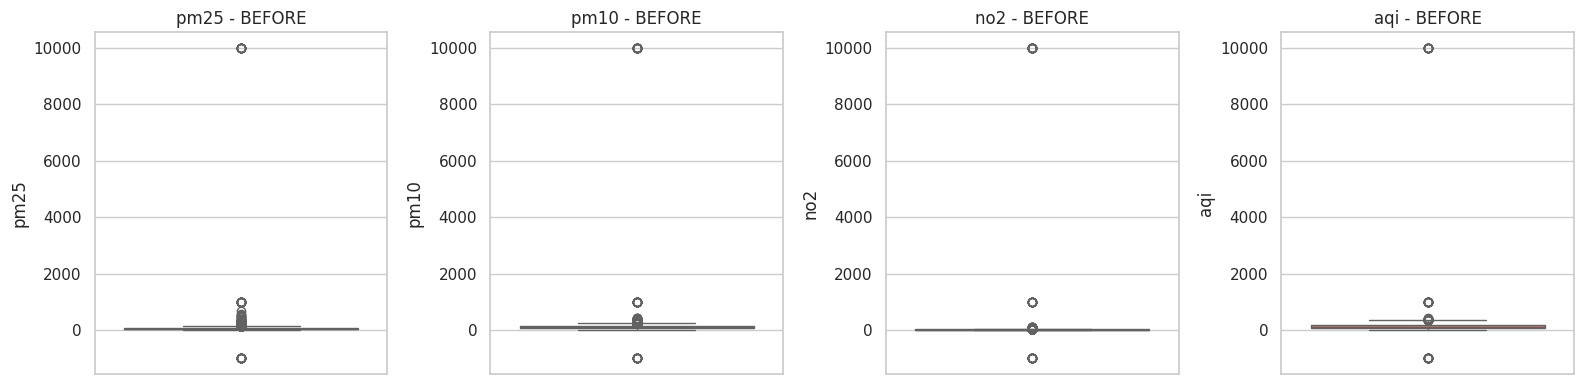

Impossible values set to NaN: {'pm25': 49, 'pm10': 45, 'no2': 45, 'aqi': 45}
Extreme spikes capped (3xIQR) in pollutant readings: {'pm25': 34, 'pm10': 7, 'no2': 10}


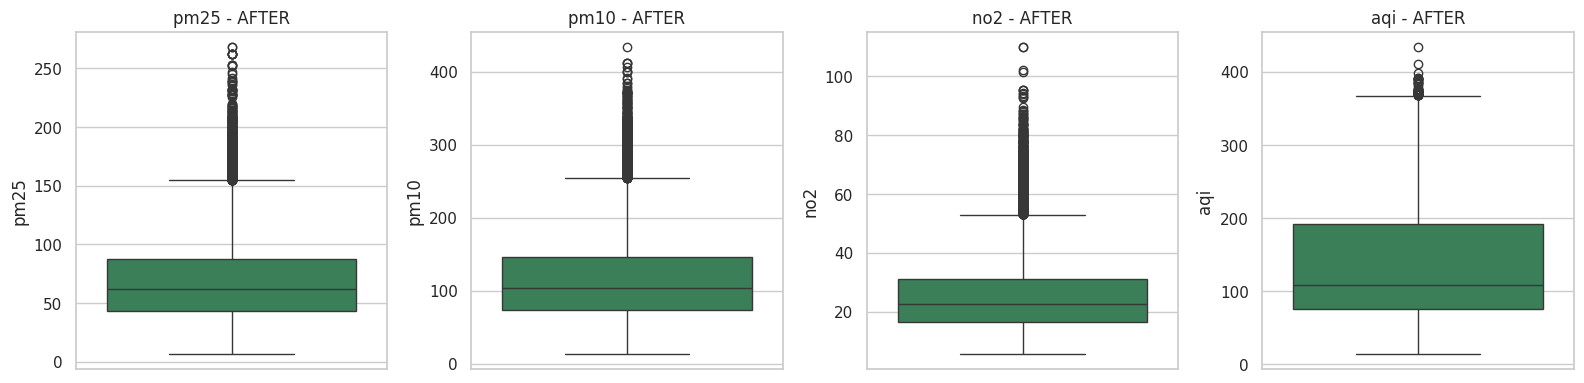

In [7]:
pol = ["pm25", "pm10", "no2", "aqi"]
limits = {"pm25": (0, 500), "pm10": (0, 800), "no2": (0, 400), "aqi": (0, 500)}   # physically possible ranges

# Boxplot BEFORE
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, pol):
    sns.boxplot(y=aq[c], ax=ax, color="tomato"); ax.set_title(f"{c} - BEFORE")
plt.tight_layout(); plt.show()

# Step 1: impossible values (negative / above limits) -> NaN
impossible = {}
for c, (lo, hi) in limits.items():
    bad = (aq[c] < lo) | (aq[c] > hi)
    impossible[c] = int(bad.sum())
    aq.loc[bad, c] = np.nan
print("Impossible values set to NaN:", impossible)

# Step 2: remaining extreme spikes -> cap with 3 x IQR fence, per station
capped = {}
for c in ["pm25", "pm10", "no2"]:      # AQI is derived from these, so it is only range-checked
    g = aq.groupby("station")[c]
    q1, q3 = g.transform(lambda s: s.quantile(0.25)), g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    lower, upper = (q1 - 3*iqr).clip(lower=0), q3 + 3*iqr
    flag = (aq[c] > upper) | (aq[c] < lower)
    capped[c] = int(flag.sum())
    aq[c] = aq[c].clip(lower=lower, upper=upper)
print("Extreme spikes capped (3xIQR) in pollutant readings:", capped)
report["impossible_values"] = impossible
report["iqr_capped"] = capped

# Boxplot AFTER
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, pol):
    sns.boxplot(y=aq[c], ax=ax, color="seagreen"); ax.set_title(f"{c} - AFTER")
plt.tight_layout(); plt.show()

### 4.4 Missing sensor readings

In [8]:
miss_before = aq[pol].isna().sum()
print("Missing before:\n", miss_before)

aq = aq.sort_values(["station", "timestamp"]).reset_index(drop=True)
for c in pol:
    # short gaps: interpolate within the same station (up to 6 hours)
    aq[c] = aq.groupby("station")[c].transform(lambda s: s.interpolate(limit=6, limit_direction="both"))
    # anything still missing: station + month median
    aq[c] = aq[c].fillna(aq.groupby(["station", aq["timestamp"].dt.month])[c].transform("median"))

aq["aqi"] = aq["aqi"].round().astype(int)
print("\nMissing after:\n", aq[pol].isna().sum())
report["aq_missing_before"] = {k: int(v) for k, v in miss_before.items()}

Missing before:
 pm25    2358
pm10    2455
no2     2446
aqi     2387
dtype: int64

Missing after:
 pm25    0
pm10    0
no2     0
aqi     0
dtype: int64


### 4.5 Weather gaps and traffic gaps

In [9]:
wx["timestamp"] = pd.to_datetime(wx["timestamp"])
tr["timestamp"] = pd.to_datetime(tr["timestamp"])
print("Weather duplicates on timestamp:", wx["timestamp"].duplicated().sum())
print("Weather missing before:\n", wx.isna().sum())
report["weather_missing_before"] = {k: int(v) for k, v in wx.isna().sum().items() if k != "timestamp"}
report["traffic_missing_before"] = int(tr["traffic_volume"].isna().sum())

wx = wx.sort_values("timestamp").set_index("timestamp")
wx["rain_mm"] = wx["rain_mm"].fillna(0)                                   # no record -> assume no rain
for c in ["wind_speed", "temperature", "humidity"]:
    wx[c] = wx[c].interpolate(method="time", limit=12).ffill().bfill()    # time-based interpolation
wx["humidity"] = wx["humidity"].clip(0, 100)
wx = wx.reset_index()

tr = tr.sort_values("timestamp").set_index("timestamp")
tr["traffic_volume"] = tr["traffic_volume"].interpolate(method="time").ffill().bfill().round().astype(int)
tr = tr.reset_index()

print("\nWeather missing after:\n", wx.isna().sum())
print("Traffic missing after:", tr["traffic_volume"].isna().sum())

cal["date"] = pd.to_datetime(cal["date"])
print("Calendar missing:", cal.isna().sum().sum())

Weather duplicates on timestamp: 0
Weather missing before:
 timestamp        0
wind_speed     265
temperature    283
humidity       289
rain_mm        170
dtype: int64

Weather missing after:
 timestamp      0
wind_speed     0
temperature    0
humidity       0
rain_mm        0
dtype: int64
Traffic missing after: 0
Calendar missing: 0


## 5. Merge at the analysis level: **station x hour**
Air quality is hourly per station, weather and traffic are hourly city-wide, calendar and station details are daily / per-station.

In [10]:
aq["date"] = aq["timestamp"].dt.normalize()

df = (aq.merge(st, on="station", how="left")
        .merge(wx, on="timestamp", how="left")
        .merge(tr, on="timestamp", how="left")
        .merge(cal, on="date", how="left"))

print("Rows in air_quality (cleaned):", len(aq), "| rows after merge:", len(df))
assert len(df) == len(aq), "Merge changed the number of rows!"
print("Total missing values after merge:", int(df.isna().sum().sum()))
print("Shape:", df.shape)
display(df.head())

df.to_csv("data/cleaned_air_quality.csv", index=False)
report["clean_shape"] = df.shape
print("Saved: data/cleaned_air_quality.csv")

Rows in air_quality (cleaned): 70272 | rows after merge: 70272
Total missing values after merge: 0
Shape: (70272, 18)


,timestamp,station,pm25,pm10,no2,aqi,date,location,land_use_type,wind_speed,temperature,humidity,rain_mm,traffic_volume,peak_flag,weekday,is_holiday,season
0,2024-01-01 00:00:00,Gandhipuram,87.5,130.6,17.1,192,2024-01-01,Central Zone,Commercial,1.06,22.4,88.5,0.0,195,0,Monday,1,Winter
1,2024-01-01 01:00:00,Gandhipuram,53.5,98.0,16.8,98,2024-01-01,Central Zone,Commercial,1.06,20.7,86.5,0.0,114,0,Monday,1,Winter
2,2024-01-01 02:00:00,Gandhipuram,86.6,132.5,15.9,160,2024-01-01,Central Zone,Commercial,0.59,21.8,82.2,0.0,98,0,Monday,1,Winter
3,2024-01-01 03:00:00,Gandhipuram,119.7,193.7,14.9,299,2024-01-01,Central Zone,Commercial,0.30,21.8,83.2,0.0,81,0,Monday,1,Winter
4,2024-01-01 04:00:00,Gandhipuram,110.6,183.1,17.1,269,2024-01-01,Central Zone,Commercial,0.56,19.6,97.4,0.0,205,0,Monday,1,Winter


Saved: data/cleaned_air_quality.csv


## 6. Exploratory Data Analysis

,pm25,pm10,no2,aqi,wind_speed,temperature,humidity,rain_mm,traffic_volume
count,70272.00,70272.00,70272.00,70272.00,70272.00,70272.00,70272.00,70272.00,70272.00
mean,67.95,114.02,25.06,138.85,2.38,28.00,75.50,0.14,949.53
std,32.97,54.09,11.17,82.74,1.17,3.83,11.84,0.74,575.00
min,6.80,13.50,5.70,14.00,0.20,18.50,36.10,0.00,64.00
25%,43.10,73.50,16.50,75.00,1.53,25.20,67.50,0.00,389.00
50%,61.70,103.70,22.80,108.00,2.32,28.00,76.20,0.00,995.00
75%,87.70,146.00,31.10,192.00,3.17,30.80,84.20,0.00,1347.00
max,268.10,433.50,109.90,434.00,8.15,37.70,100.00,18.80,2560.00


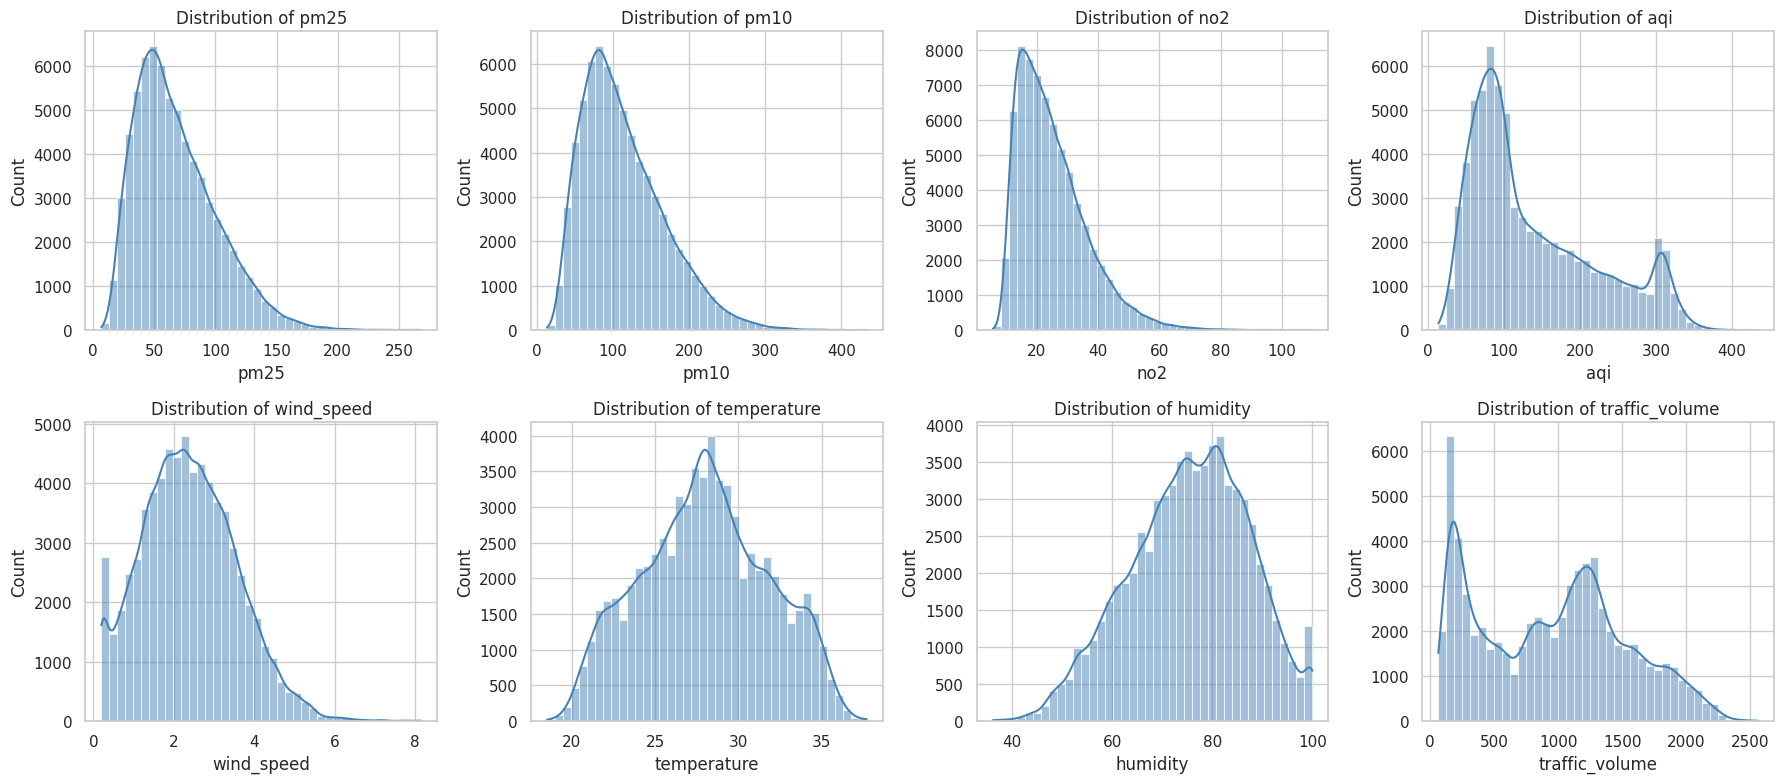

In [11]:
display(df[["pm25", "pm10", "no2", "aqi", "wind_speed", "temperature", "humidity", "rain_mm", "traffic_volume"]].describe().round(2))

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), ["pm25", "pm10", "no2", "aqi", "wind_speed", "temperature", "humidity", "traffic_volume"]):
    sns.histplot(df[c], bins=40, kde=True, ax=ax, color="steelblue"); ax.set_title(f"Distribution of {c}")
plt.tight_layout(); plt.show()

### Q1. Which stations have poorer air quality?

,mean_AQI,location,land_use_type
station,,,
Ukkadam,190.6,South Zone,Transport Hub
Singanallur,181.8,East Zone,Industrial
Kuniyamuthur,171.1,South Zone,Industrial
Gandhipuram,162.0,Central Zone,Commercial
RS Puram,140.7,Central Zone,Commercial
Peelamedu,103.5,East Zone,Residential
Saravanampatti,93.8,North Zone,Residential
Vadavalli,67.2,West Zone,Green Zone


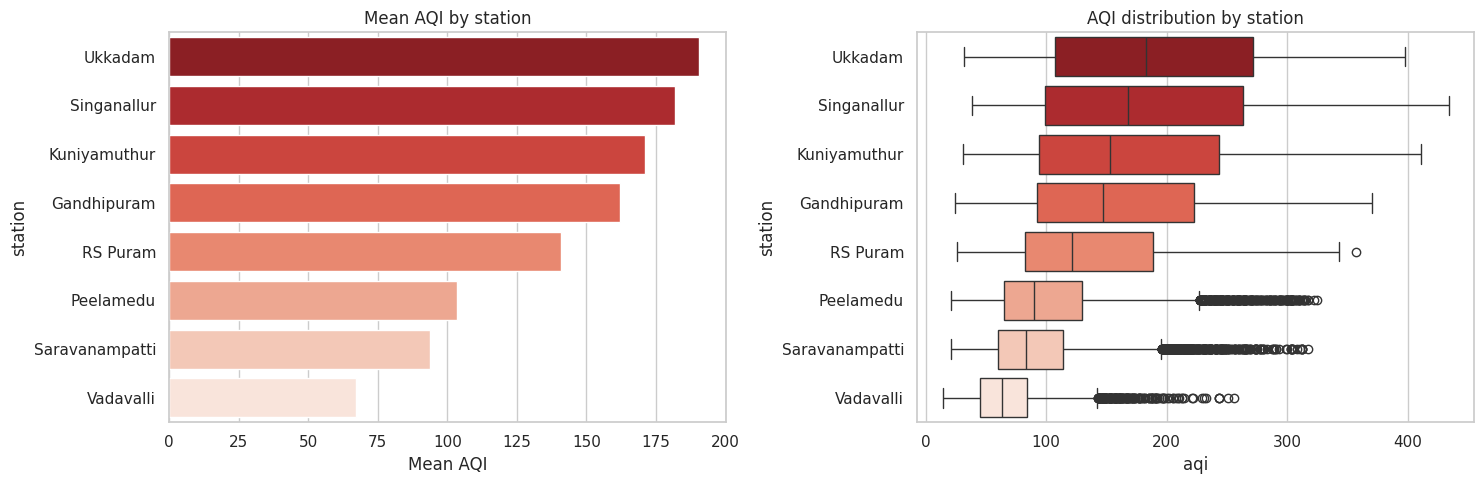

Mean AQI by land-use type:
 land_use_type
Transport Hub    190.6
Industrial       176.4
Commercial       151.4
Residential       98.7
Green Zone        67.2
Name: aqi, dtype: float64

>> Worst: Ukkadam (190.6) | Best: Vadavalli (67.2)


In [12]:
stn = df.groupby("station")["aqi"].mean().sort_values(ascending=False)
display(stn.round(1).to_frame("mean_AQI").join(st.set_index("station")))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=stn.values, y=stn.index, ax=ax[0], palette="Reds_r"); ax[0].set_title("Mean AQI by station"); ax[0].set_xlabel("Mean AQI")
sns.boxplot(data=df, x="aqi", y="station", order=stn.index, ax=ax[1], palette="Reds_r"); ax[1].set_title("AQI distribution by station")
plt.tight_layout(); plt.show()

lu = df.groupby("land_use_type")["aqi"].mean().sort_values(ascending=False)
print("Mean AQI by land-use type:\n", lu.round(1))
findings["worst_station"] = (stn.index[0], round(float(stn.iloc[0]), 1))
findings["best_station"] = (stn.index[-1], round(float(stn.iloc[-1]), 1))
findings["worst_landuse"] = (lu.index[0], round(float(lu.iloc[0]), 1))
print(f"\n>> Worst: {stn.index[0]} ({stn.iloc[0]:.1f}) | Best: {stn.index[-1]} ({stn.iloc[-1]:.1f})")

### Q2. What times show higher pollution?

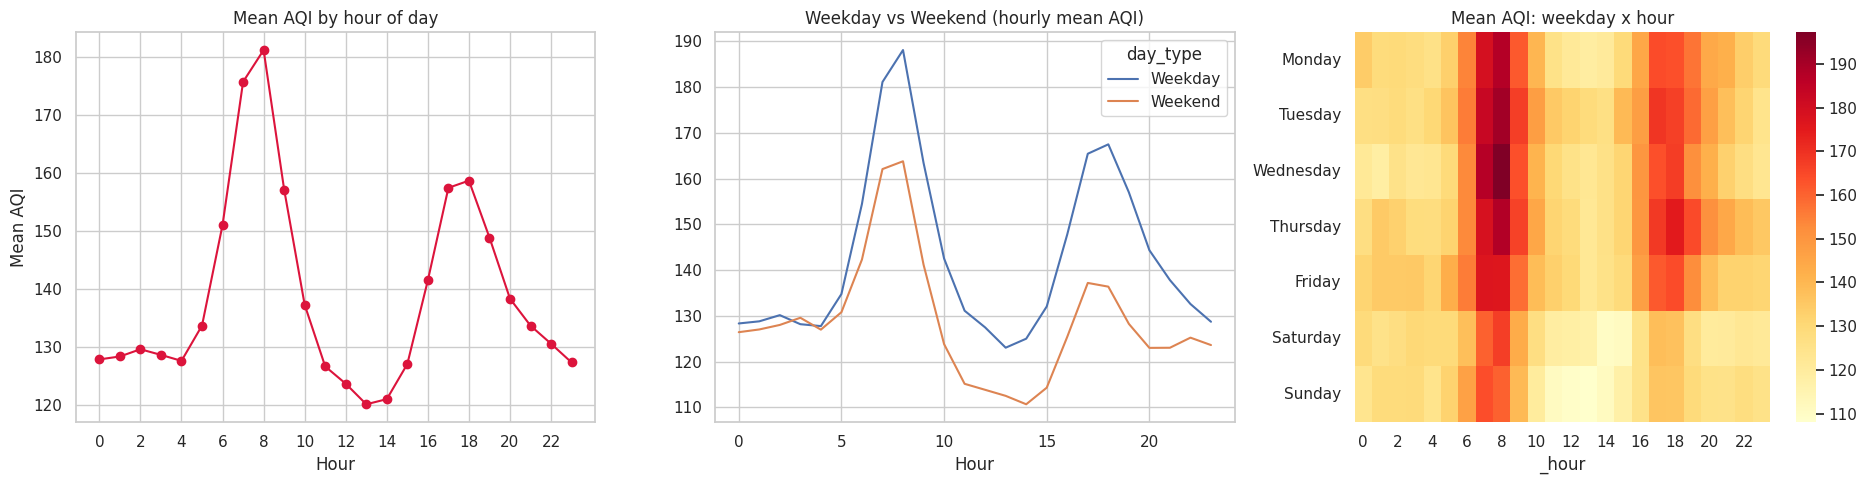

Top 3 pollution hours: [(8, 181.2), (7, 175.7), (18, 158.7)] | Lowest hour: (13, 120.1)
Mean AQI weekday vs weekend:
 timestamp
Weekday    142.8
Weekend    128.8
Name: aqi, dtype: float64


In [13]:
df["_hour"] = df["timestamp"].dt.hour
df["_dow"] = df["timestamp"].dt.day_name()
hr = df.groupby("_hour")["aqi"].mean()

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
ax[0].plot(hr.index, hr.values, marker="o", color="crimson"); ax[0].set_title("Mean AQI by hour of day")
ax[0].set_xlabel("Hour"); ax[0].set_ylabel("Mean AQI"); ax[0].set_xticks(range(0, 24, 2))

wk = df.assign(day_type=np.where(df["timestamp"].dt.dayofweek >= 5, "Weekend", "Weekday")).groupby(["_hour", "day_type"])["aqi"].mean().unstack()
wk.plot(ax=ax[1]); ax[1].set_title("Weekday vs Weekend (hourly mean AQI)"); ax[1].set_xlabel("Hour")

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
hm = df.pivot_table(index="_dow", columns="_hour", values="aqi", aggfunc="mean").reindex(order)
sns.heatmap(hm, cmap="YlOrRd", ax=ax[2]); ax[2].set_title("Mean AQI: weekday x hour"); ax[2].set_ylabel("")
plt.tight_layout(); plt.show()

top_hours = hr.sort_values(ascending=False).head(3)
findings["peak_hours"] = [(int(h), round(float(v), 1)) for h, v in top_hours.items()]
findings["lowest_hour"] = (int(hr.idxmin()), round(float(hr.min()), 1))
print("Top 3 pollution hours:", findings["peak_hours"], "| Lowest hour:", findings["lowest_hour"])
print("Mean AQI weekday vs weekend:\n", df.groupby(df["timestamp"].dt.dayofweek >= 5)["aqi"].mean().round(1).rename({False: "Weekday", True: "Weekend"}))

### Q3. How does wind relate to PM2.5?

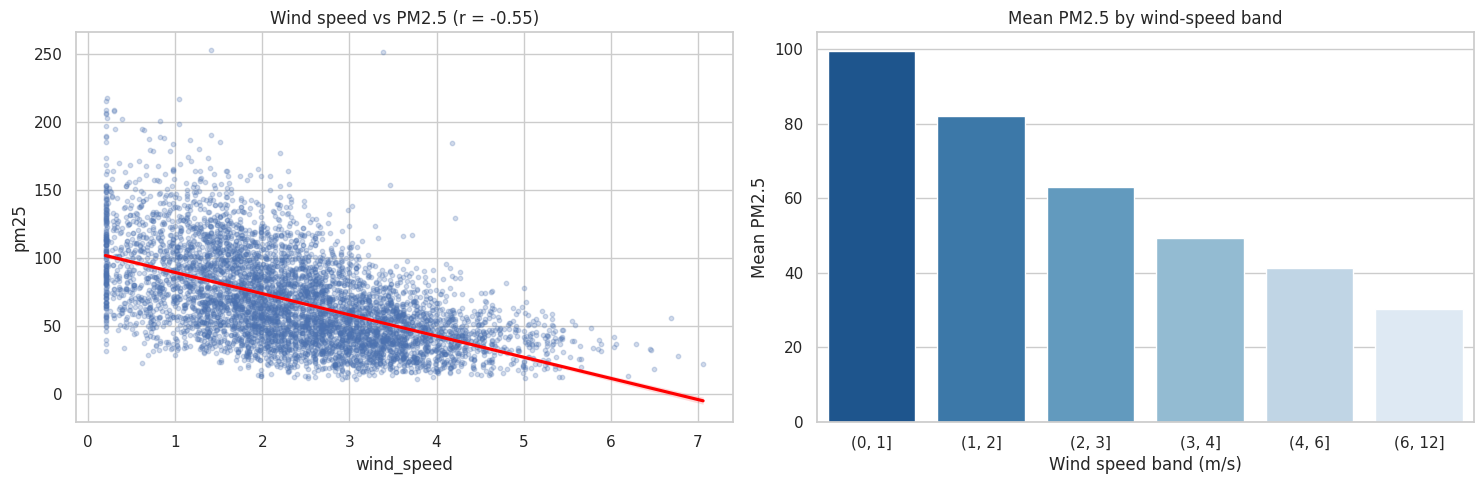

Correlation (wind, PM2.5): -0.551
wind_speed
(0, 1]     99.5
(1, 2]     82.1
(2, 3]     63.0
(3, 4]     49.2
(4, 6]     41.2
(6, 12]    30.2
Name: pm25, dtype: float64


In [14]:
samp = df.sample(6000, random_state=1)
corr_w = df["wind_speed"].corr(df["pm25"])
findings["corr_wind_pm25"] = round(float(corr_w), 3)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.regplot(data=samp, x="wind_speed", y="pm25", scatter_kws={"alpha": 0.25, "s": 10}, line_kws={"color": "red"}, ax=ax[0])
ax[0].set_title(f"Wind speed vs PM2.5 (r = {corr_w:.2f})")

bins = pd.cut(df["wind_speed"], [0, 1, 2, 3, 4, 6, 12])
wb = df.groupby(bins)["pm25"].mean()
sns.barplot(x=wb.index.astype(str), y=wb.values, ax=ax[1], palette="Blues_r"); ax[1].set_title("Mean PM2.5 by wind-speed band")
ax[1].set_xlabel("Wind speed band (m/s)"); ax[1].set_ylabel("Mean PM2.5")
plt.tight_layout(); plt.show()
print("Correlation (wind, PM2.5):", round(corr_w, 3))
print(wb.round(1))

### Q4. Does traffic volume align with AQI?

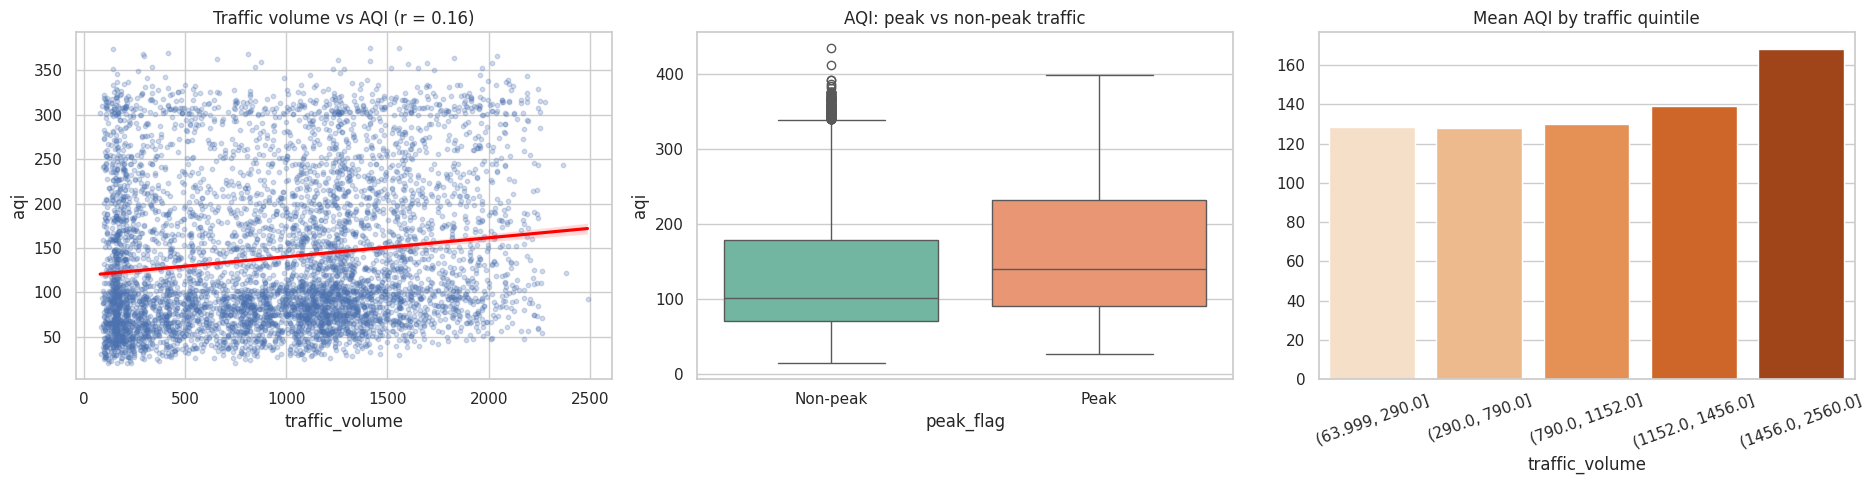

Correlation (traffic, AQI): 0.165
Mean AQI peak vs non-peak: {0: 130.7, 1: 163.2}
Mean NO2 peak vs non-peak: {0: 21.8, 1: 34.8}


In [15]:
corr_t = df["traffic_volume"].corr(df["aqi"])
findings["corr_traffic_aqi"] = round(float(corr_t), 3)
pk = df.groupby("peak_flag")["aqi"].mean()
findings["peak_vs_offpeak_aqi"] = (round(float(pk.get(1, np.nan)), 1), round(float(pk.get(0, np.nan)), 1))

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
sns.regplot(data=samp, x="traffic_volume", y="aqi", scatter_kws={"alpha": 0.25, "s": 10}, line_kws={"color": "red"}, ax=ax[0])
ax[0].set_title(f"Traffic volume vs AQI (r = {corr_t:.2f})")
sns.boxplot(data=df, x="peak_flag", y="aqi", ax=ax[1], palette="Set2"); ax[1].set_xticklabels(["Non-peak", "Peak"]); ax[1].set_title("AQI: peak vs non-peak traffic")
tb = df.groupby(pd.qcut(df["traffic_volume"], 5))["aqi"].mean()
sns.barplot(x=tb.index.astype(str), y=tb.values, ax=ax[2], palette="Oranges"); ax[2].set_title("Mean AQI by traffic quintile"); ax[2].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print("Correlation (traffic, AQI):", round(corr_t, 3))
print("Mean AQI peak vs non-peak:", pk.round(1).to_dict())
print("Mean NO2 peak vs non-peak:", df.groupby("peak_flag")["no2"].mean().round(1).to_dict())

### Q5. How does rain affect pollution?

,pm25,pm10,aqi
_rain,,,
No rain,70.0,117.3,143.7
Rain,40.8,70.4,75.0


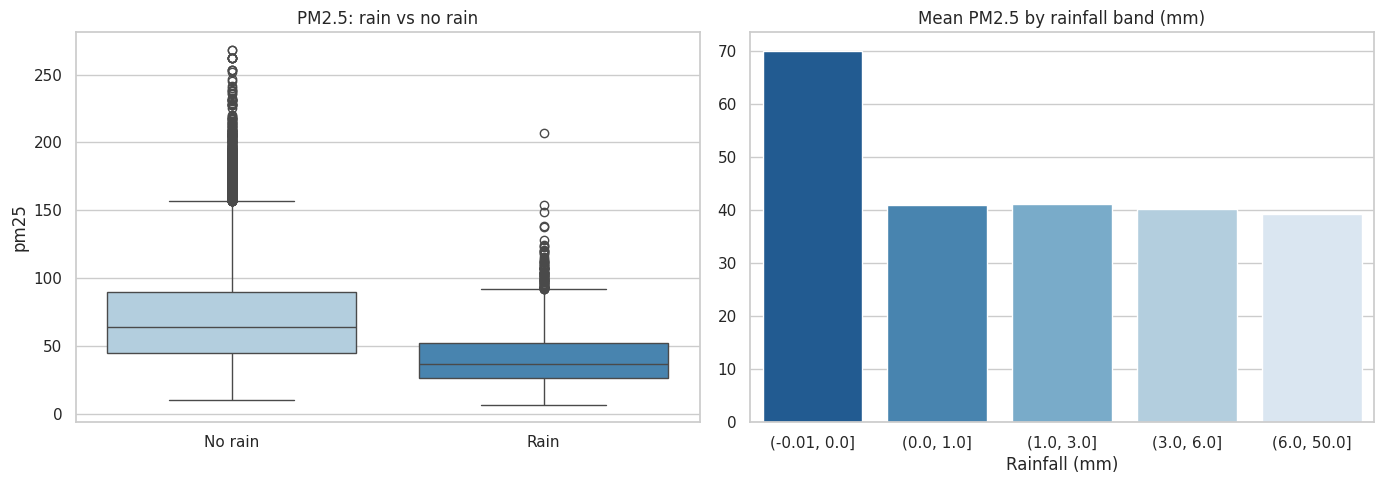

>> PM2.5 is about 41.7% lower during rain


In [16]:
df["_rain"] = np.where(df["rain_mm"] > 0, "Rain", "No rain")
rn = df.groupby("_rain")[["pm25", "pm10", "aqi"]].mean().round(1)
display(rn)
drop_pct = (1 - rn.loc["Rain", "pm25"]/rn.loc["No rain", "pm25"])*100
findings["rain_pm25"] = (float(rn.loc["Rain", "pm25"]), float(rn.loc["No rain", "pm25"]), round(float(drop_pct), 1))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="_rain", y="pm25", ax=ax[0], palette="Blues"); ax[0].set_title("PM2.5: rain vs no rain"); ax[0].set_xlabel("")
rb = df.groupby(pd.cut(df["rain_mm"], [-0.01, 0, 1, 3, 6, 50]))["pm25"].mean()
sns.barplot(x=rb.index.astype(str), y=rb.values, ax=ax[1], palette="Blues_r"); ax[1].set_title("Mean PM2.5 by rainfall band (mm)"); ax[1].set_xlabel("Rainfall (mm)")
plt.tight_layout(); plt.show()
print(f">> PM2.5 is about {drop_pct:.1f}% lower during rain")

### Q6. Which seasons show recurring peaks?

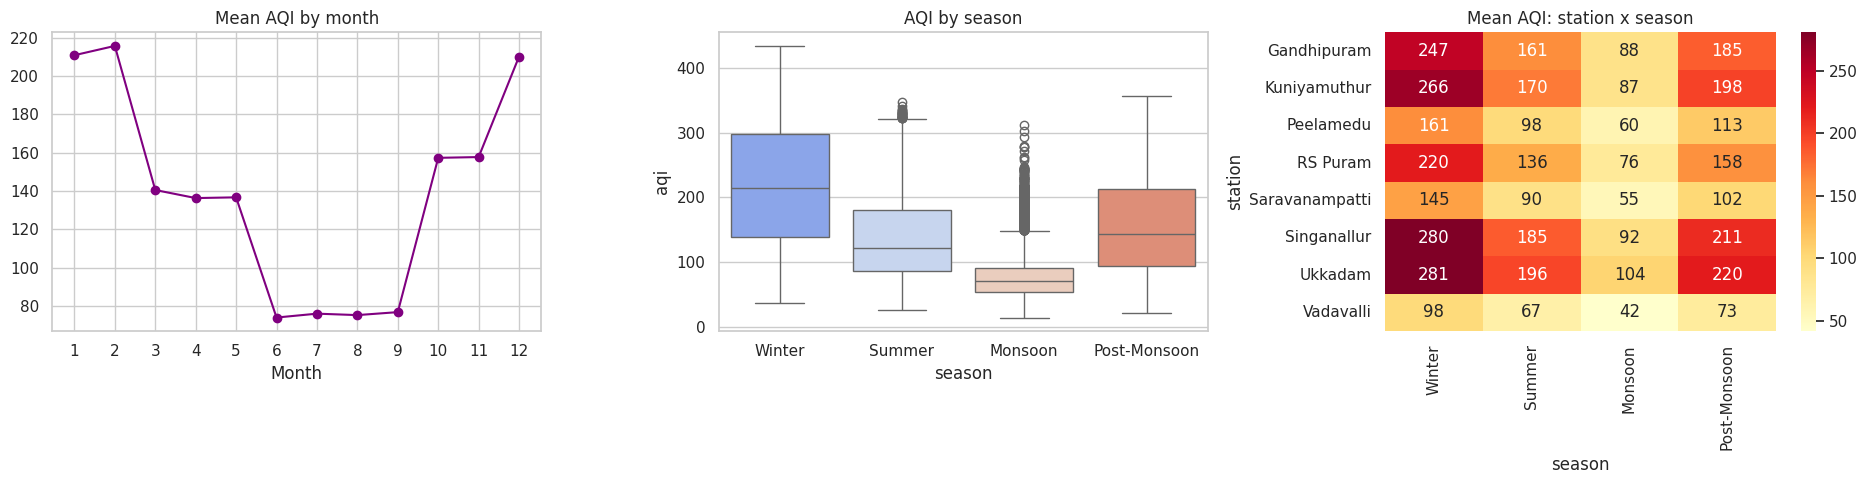

season
Winter          212.3
Summer          137.9
Monsoon          75.5
Post-Monsoon    157.5
Name: aqi, dtype: float64
>> Peak season: Winter | Peak month: 2


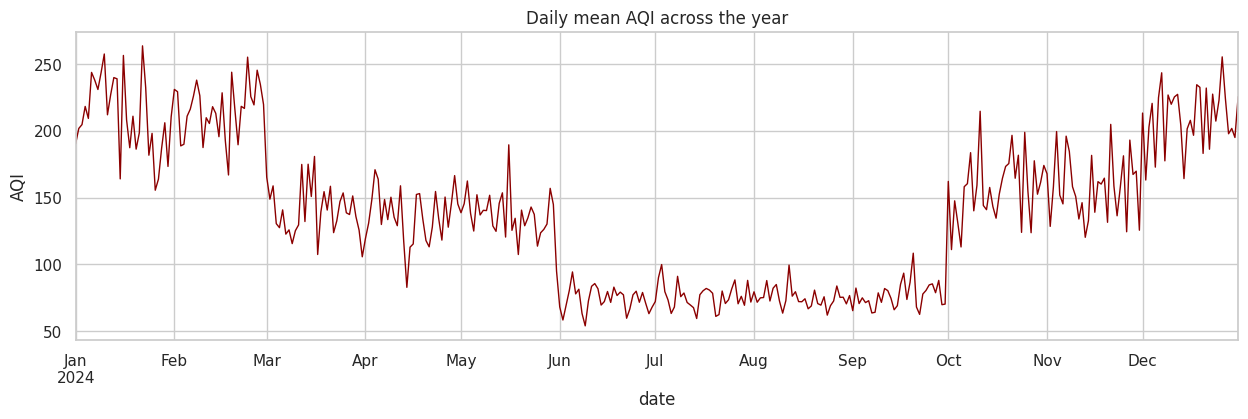

In [17]:
order_s = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]
se = df.groupby("season")["aqi"].mean().reindex(order_s)
mo = df.groupby(df["timestamp"].dt.month)["aqi"].mean()
findings["season_mean"] = se.round(1).to_dict()
findings["peak_season"] = se.idxmax()
findings["peak_month"] = int(mo.idxmax())

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
ax[0].plot(mo.index, mo.values, marker="o", color="purple"); ax[0].set_title("Mean AQI by month"); ax[0].set_xticks(range(1, 13)); ax[0].set_xlabel("Month")
sns.boxplot(data=df, x="season", y="aqi", order=order_s, ax=ax[1], palette="coolwarm"); ax[1].set_title("AQI by season")
sp = df.pivot_table(index="station", columns="season", values="aqi", aggfunc="mean")[order_s]
sns.heatmap(sp, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax[2]); ax[2].set_title("Mean AQI: station x season")
plt.tight_layout(); plt.show()
print(se.round(1)); print(">> Peak season:", findings["peak_season"], "| Peak month:", findings["peak_month"])

daily = df.groupby("date")["aqi"].mean()
plt.figure(figsize=(15, 4)); daily.plot(color="darkred", linewidth=1); plt.title("Daily mean AQI across the year"); plt.ylabel("AQI"); plt.show()

### Correlation heatmap

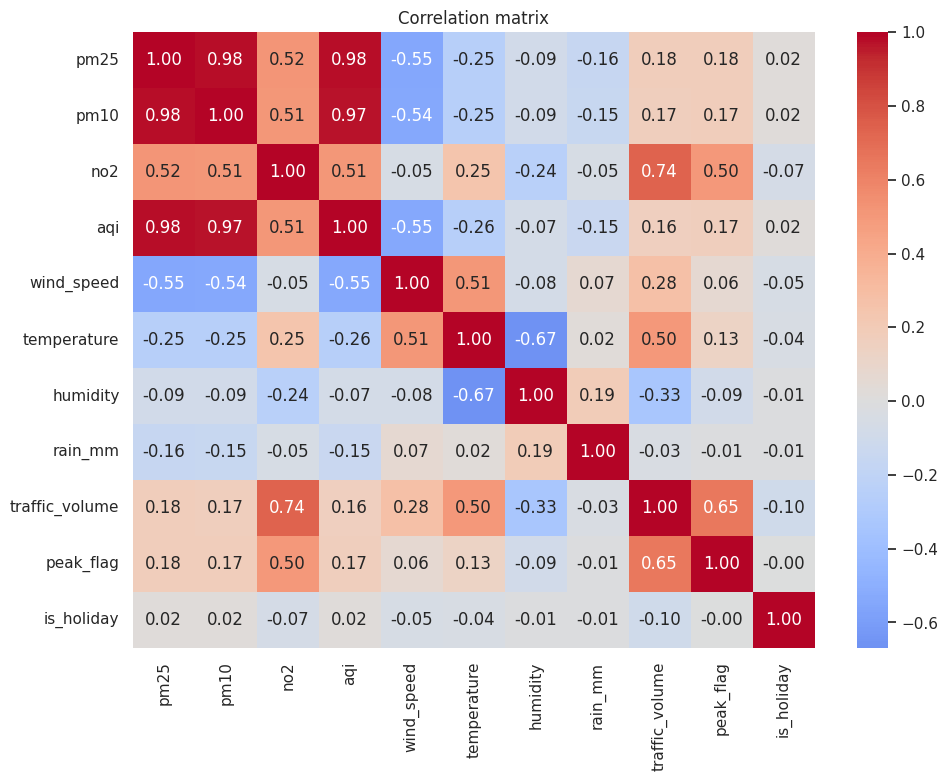

In [18]:
num_cols = ["pm25", "pm10", "no2", "aqi", "wind_speed", "temperature", "humidity", "rain_mm", "traffic_volume", "peak_flag", "is_holiday"]
plt.figure(figsize=(11, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()
df.drop(columns=["_hour", "_dow", "_rain"], inplace=True)

## 7. Feature engineering and encoding

In [19]:
fe = df.sort_values(["station", "timestamp"]).reset_index(drop=True).copy()
g = fe.groupby("station")

# --- time features
fe["hour"] = fe["timestamp"].dt.hour
fe["day_of_week"] = fe["timestamp"].dt.dayofweek
fe["month"] = fe["timestamp"].dt.month
fe["is_weekend"] = (fe["day_of_week"] >= 5).astype(int)
fe["is_night"] = fe["hour"].isin([22, 23, 0, 1, 2, 3, 4, 5]).astype(int)
fe["hour_sin"] = np.sin(2*np.pi*fe["hour"]/24)
fe["hour_cos"] = np.cos(2*np.pi*fe["hour"]/24)
fe["time_of_day"] = pd.cut(fe["hour"], [-1, 5, 11, 16, 20, 23], labels=["Night", "Morning", "Afternoon", "Evening", "Late-Night"]).astype(str)
fe["time_of_day"] = fe["time_of_day"].replace({"Late-Night": "Night"})

# --- weather features
fe["is_raining"] = (fe["rain_mm"] > 0).astype(int)
fe["rain_last_3h"] = g["rain_mm"].transform(lambda s: s.rolling(3, min_periods=1).sum())
fe["calm_wind"] = (fe["wind_speed"] < 1.5).astype(int)
fe["wind_band"] = pd.cut(fe["wind_speed"], [0, 1.5, 3, 5, 20], labels=["Calm", "Light", "Moderate", "Strong"]).astype(str)
fe["traffic_per_wind"] = fe["traffic_volume"]/(fe["wind_speed"] + 1)
fe["temp_humidity"] = fe["temperature"]*fe["humidity"]/100

# --- lag and rolling features (history only -> no leakage)
fe["pm25_lag1"] = g["pm25"].shift(1)
fe["pm25_lag24"] = g["pm25"].shift(24)
fe["pm25_roll24"] = g["pm25"].transform(lambda s: s.shift(1).rolling(24, min_periods=12).mean())

# --- AQI category (Indian AQI bands)
fe["aqi_category"] = pd.cut(fe["aqi"], [-1, 50, 100, 200, 300, 400, 500],
                            labels=["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"])
print(fe["aqi_category"].value_counts())

# --- encoding
fe["station_code"] = fe["station"].astype("category").cat.codes                                   # label encoding
fe["aqi_category_code"] = fe["aqi_category"].cat.codes                                            # ordinal
fe = pd.get_dummies(fe, columns=["season", "land_use_type", "time_of_day", "wind_band"], dtype=int)  # one-hot

display(fe.head())
print("Engineered table shape:", fe.shape)

aqi_category
Satisfactory    26317
Moderate        22045
Poor            10969
Good             5671
Very Poor        5268
Severe              2
Name: count, dtype: int64


,timestamp,station,pm25,pm10,no2,aqi,date,location,wind_speed,temperature,humidity,rain_mm,traffic_volume,peak_flag,weekday,is_holiday,hour,day_of_week,month,is_weekend,is_night,hour_sin,hour_cos,is_raining,rain_last_3h,calm_wind,traffic_per_wind,temp_humidity,pm25_lag1,pm25_lag24,pm25_roll24,aqi_category,station_code,aqi_category_code,season_Monsoon,season_Post-Monsoon,season_Summer,season_Winter,land_use_type_Commercial,land_use_type_Green Zone,land_use_type_Industrial,land_use_type_Residential,land_use_type_Transport Hub,time_of_day_Afternoon,time_of_day_Evening,time_of_day_Morning,time_of_day_Night,wind_band_Calm,wind_band_Light,wind_band_Moderate,wind_band_Strong
0,2024-01-01 00:00:00,Gandhipuram,87.5,130.6,17.1,192,2024-01-01,Central Zone,1.06,22.4,88.5,0.0,195,0,Monday,1,0,0,1,0,1,0.000000,1.000000,0,0.0,1,94.660194,19.8240,NaN,NaN,NaN,Moderate,0,2,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,0
1,2024-01-01 01:00:00,Gandhipuram,53.5,98.0,16.8,98,2024-01-01,Central Zone,1.06,20.7,86.5,0.0,114,0,Monday,1,1,0,1,0,1,0.258819,0.965926,0,0.0,1,55.339806,17.9055,87.5,NaN,NaN,Satisfactory,0,1,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,0
2,2024-01-01 02:00:00,Gandhipuram,86.6,132.5,15.9,160,2024-01-01,Central Zone,0.59,21.8,82.2,0.0,98,0,Monday,1,2,0,1,0,1,0.500000,0.866025,0,0.0,1,61.635220,17.9196,53.5,NaN,NaN,Moderate,0,2,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,0
3,2024-01-01 03:00:00,Gandhipuram,119.7,193.7,14.9,299,2024-01-01,Central Zone,0.30,21.8,83.2,0.0,81,0,Monday,1,3,0,1,0,1,0.707107,0.707107,0,0.0,1,62.307692,18.1376,86.6,NaN,NaN,Poor,0,3,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,0
4,2024-01-01 04:00:00,Gandhipuram,110.6,183.1,17.1,269,2024-01-01,Central Zone,0.56,19.6,97.4,0.0,205,0,Monday,1,4,0,1,0,1,0.866025,0.500000,0,0.0,1,131.410256,19.0904,119.7,NaN,NaN,Poor,0,3,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,0


Engineered table shape: (70272, 51)


## 8. Feature selection and dimensionality reduction
**Target:** `aqi`.
`pm25`, `pm10` and `no2` are **excluded** as inputs – AQI is computed from them (that would be data leakage).
The question asks how *weather, location and time* drive air quality, so the main feature set contains those drivers only.
Lag features are used later in a second model.

37 candidate features:
 ['wind_speed', 'temperature', 'humidity', 'rain_mm', 'traffic_volume', 'peak_flag', 'is_holiday', 'hour', 'day_of_week', 'month', 'is_weekend', 'is_night', 'hour_sin', 'hour_cos', 'is_raining', 'rain_last_3h', 'calm_wind', 'traffic_per_wind', 'temp_humidity', 'station_code', 'season_Monsoon', 'season_Post-Monsoon', 'season_Summer', 'season_Winter', 'land_use_type_Commercial', 'land_use_type_Green Zone', 'land_use_type_Industrial', 'land_use_type_Residential', 'land_use_type_Transport Hub', 'time_of_day_Afternoon', 'time_of_day_Evening', 'time_of_day_Morning', 'time_of_day_Night', 'wind_band_Calm', 'wind_band_Light', 'wind_band_Moderate', 'wind_band_Strong']

Dropped for high correlation (>0.9): ['time_of_day_Night', 'wind_band_Calm']


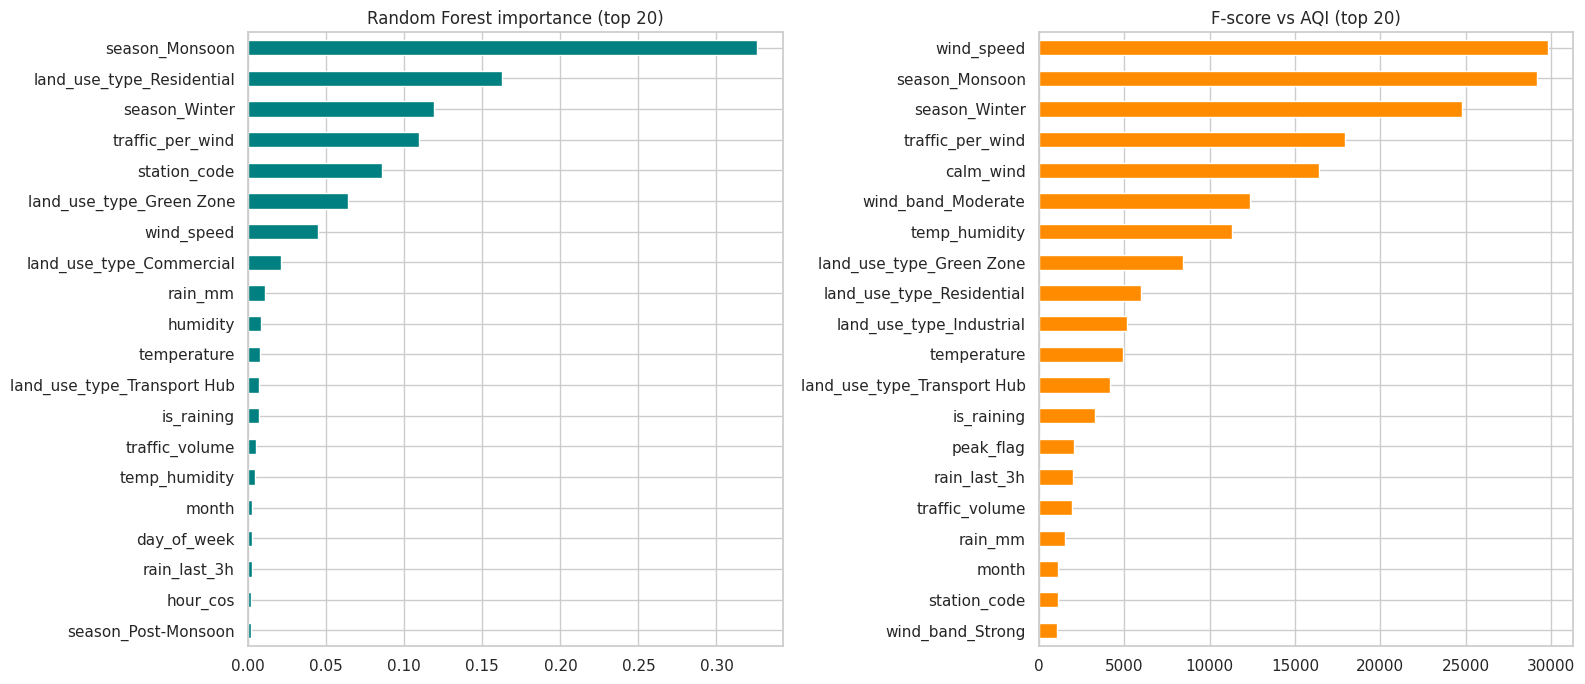


SELECTED FEATURES (10):
 1. season_Monsoon               importance = 0.3261
 2. land_use_type_Residential    importance = 0.1627
 3. season_Winter                importance = 0.1191
 4. traffic_per_wind             importance = 0.1093
 5. station_code                 importance = 0.0858
 6. land_use_type_Green Zone     importance = 0.0642
 7. wind_speed                   importance = 0.0448
 8. land_use_type_Commercial     importance = 0.0210
 9. rain_mm                      importance = 0.0108
10. humidity                     importance = 0.0083


In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import f_regression
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

target = "aqi"
lag_feats = ["pm25_lag1", "pm25_lag24", "pm25_roll24"]
drop_cols = ["timestamp", "date", "station", "location", "weekday", "aqi_category", "aqi_category_code",
             "pm25", "pm10", "no2", "aqi"] + lag_feats
candidates = [c for c in fe.columns if c not in drop_cols]
print(len(candidates), "candidate features:\n", candidates)

# Step 1: remove one of every pair with |correlation| > 0.9
cm = fe[candidates].corr().abs()
upper = cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > 0.9).any()]
print("\nDropped for high correlation (>0.9):", to_drop)
cand2 = [c for c in candidates if c not in to_drop]

# Step 2: statistical score (F-test) + Random Forest importance
Xs, ys = fe[cand2], fe[target]
f_scores, _ = f_regression(Xs, ys)
fs = pd.Series(f_scores, index=cand2).sort_values(ascending=False)

sub = fe.sample(25000, random_state=7)
rf_sel = RandomForestRegressor(n_estimators=60, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=42)
rf_sel.fit(sub[cand2], sub[target])
imp = pd.Series(rf_sel.feature_importances_, index=cand2).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
imp.head(20).sort_values().plot(kind="barh", ax=ax[0], color="teal"); ax[0].set_title("Random Forest importance (top 20)")
fs.head(20).sort_values().plot(kind="barh", ax=ax[1], color="darkorange"); ax[1].set_title("F-score vs AQI (top 20)")
plt.tight_layout(); plt.show()

# Final selection: features that make up 95 % of total importance
cum = imp.cumsum()/imp.sum()
selected = list(imp[cum.shift(fill_value=0) < 0.95].index)
print(f"\nSELECTED FEATURES ({len(selected)}):")
for i, f in enumerate(selected, 1):
    print(f"{i:>2}. {f:<28} importance = {imp[f]:.4f}")
report["n_candidates"] = len(candidates)
report["dropped_corr"] = to_drop
report["selected_features"] = selected

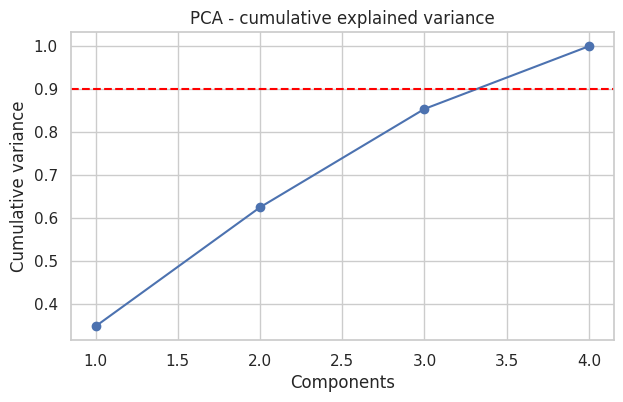

Continuous features used for PCA: ['traffic_per_wind', 'wind_speed', 'rain_mm', 'humidity']
4 of 4 components explain >= 90% of the variance


In [21]:
# Optional: PCA on the continuous selected features (dimensionality reduction)
cont = [c for c in selected if fe[c].nunique() > 10]
Z = StandardScaler().fit_transform(fe[cont])
pca = PCA().fit(Z)
cumvar = np.cumsum(pca.explained_variance_ratio_)
k = int(np.argmax(cumvar >= 0.90) + 1)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cumvar)+1), cumvar, marker="o"); plt.axhline(0.9, color="red", ls="--")
plt.title("PCA - cumulative explained variance"); plt.xlabel("Components"); plt.ylabel("Cumulative variance"); plt.show()
print(f"Continuous features used for PCA: {cont}")
print(f"{k} of {len(cont)} components explain >= 90% of the variance")
report["pca"] = (k, len(cont))

## 9. Machine-learning model (needed for the answer sheet)
Goal: predict **AQI**. A *time-based* split is used (first 80 % of the timeline = train, last 20 % = test) so the model is tested on future data.

* **Model A** – drivers only (weather, location, time, traffic)
* **Model B** – drivers + recent pollution history (lag/rolling PM2.5)

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline

cut = fe["timestamp"].quantile(0.80)
train, test = fe[fe["timestamp"] <= cut], fe[fe["timestamp"] > cut]
print("Train rows:", len(train), "| Test rows:", len(test), "| split date:", cut)

def metrics(y, p):
    return {"RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

results, preds = {}, {}

# Model A
Xtr, Xte = train[selected], test[selected]
lr = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, train[target])
results["A: Linear Regression (drivers)"] = metrics(test[target], lr.predict(Xte))
rfA = RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=3, n_jobs=-1, random_state=42).fit(Xtr, train[target])
preds["A"] = rfA.predict(Xte)
results["A: Random Forest (drivers)"] = metrics(test[target], preds["A"])

# Model B (lag features need history -> drop first rows of each station)
featB = selected + lag_feats
trB, teB = train.dropna(subset=lag_feats), test.dropna(subset=lag_feats)
rfB = RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=3, n_jobs=-1, random_state=42).fit(trB[featB], trB[target])
preds["B"] = rfB.predict(teB[featB])
results["B: Random Forest (drivers + lag)"] = metrics(teB[target], preds["B"])

res = pd.DataFrame(results).T.round(3)
display(res)
report["model_results"] = res
report["split"] = (len(train), len(test))

Train rows: 56224 | Test rows: 14048 | split date: 2024-10-19 19:00:00


,RMSE,MAE,R2
A: Linear Regression (drivers),51.139,40.124,0.620
A: Random Forest (drivers),40.460,29.692,0.762
B: Random Forest (drivers + lag),33.439,24.955,0.838


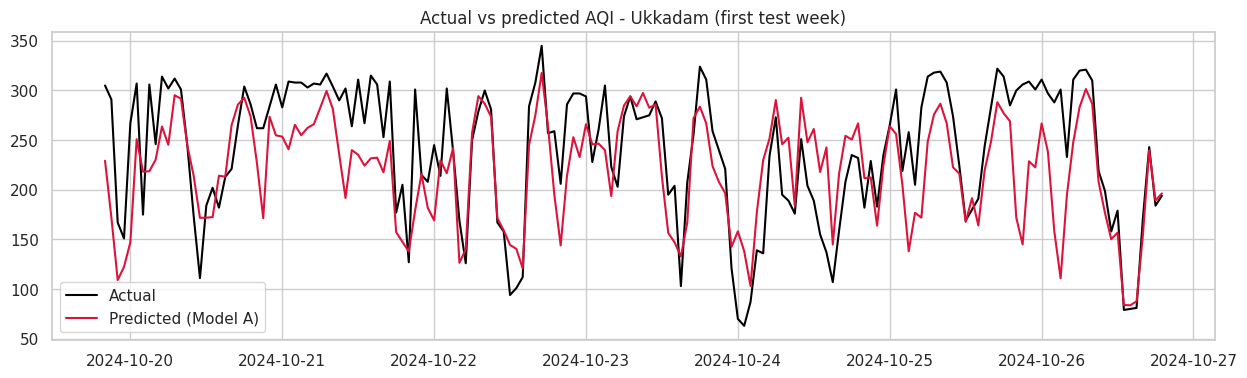

AQI-category accuracy of Model A (predicted band == actual band): 0.659

Top 5 drivers of AQI (Model A):
 season_Monsoon               0.345
land_use_type_Residential    0.155
season_Winter                0.123
traffic_per_wind             0.121
station_code                 0.084
dtype: float64


In [23]:
# Actual vs predicted (one station, one week of the test period) + AQI category accuracy
t = test.assign(pred=preds["A"])
one = t[t["station"] == findings["worst_station"][0]].head(24*7)
plt.figure(figsize=(15, 4))
plt.plot(one["timestamp"], one["aqi"], label="Actual", color="black")
plt.plot(one["timestamp"], one["pred"], label="Predicted (Model A)", color="crimson")
plt.title(f"Actual vs predicted AQI - {findings['worst_station'][0]} (first test week)"); plt.legend(); plt.show()

bins_, labs_ = [-1, 50, 100, 200, 300, 400, 500], [0, 1, 2, 3, 4, 5]
act_c = pd.cut(test[target], bins_, labels=labs_).astype(int)
prd_c = pd.cut(pd.Series(preds["A"], index=test.index).clip(0, 500), bins_, labels=labs_).astype(int)
cat_acc = (act_c == prd_c).mean()
print(f"AQI-category accuracy of Model A (predicted band == actual band): {cat_acc:.3f}")
report["cat_acc"] = round(float(cat_acc), 3)

fi = pd.Series(rfA.feature_importances_, index=selected).sort_values(ascending=False)
print("\nTop 5 drivers of AQI (Model A):\n", fi.head(5).round(3))

## 10. Save outputs

In [24]:
fe.to_csv("data/air_quality_features.csv", index=False)
pd.Series(selected, name="selected_features").to_csv("data/selected_features.csv", index=False)
print(os.listdir("data"))

with zipfile.ZipFile("CH20_data_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in os.listdir("data"):
        z.write(os.path.join("data", f))
print("Zipped -> CH20_data_outputs.zip")
try:
    from google.colab import files
    files.download("CH20_data_outputs.zip")      # downloads the zip to your laptop
except Exception as e:
    print("Not running in Colab - download skipped")

['air_quality_features.csv', 'calendar.csv', 'selected_features.csv', 'traffic.csv', 'stations.csv', 'air_quality.csv', 'cleaned_air_quality.csv', 'weather.csv']
Zipped -> CH20_data_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Answer-sheet summary (copy these REAL numbers)

In [25]:
best = report["model_results"]
print("="*70)
print("ROUND 2 SUMMARY  -  CH20 AIR QUALITY INSIGHT")
print("="*70)
print("\n[DATASET]")
print("Files: air_quality, stations, weather, traffic, calendar (synthetic, 2024 hourly, 8 stations)")
for k in report["raw_rows"]:
    print(f"  {k:<12} rows={report['raw_rows'][k]:>6}  cols={report['raw_cols'][k]}")
print("Cleaned merged table (rows, cols):", report["clean_shape"])

print("\n[PREPROCESSING]")
print("Missing in air quality (before):", report["aq_missing_before"])
print("Missing in weather (before):", report["weather_missing_before"], "| traffic:", report["traffic_missing_before"])
print("Duplicates removed:", report["duplicates_removed"])
print("Station spellings:", report["station_spellings_before"], "->", report["station_spellings_after"])
print("Impossible values -> NaN:", report["impossible_values"])
print("Outliers capped (3xIQR):", report["iqr_capped"])

print("\n[EDA FINDINGS]")
print("Worst station:", findings["worst_station"], "| best:", findings["best_station"], "| worst land use:", findings["worst_landuse"])
print("Peak hours (hour, mean AQI):", findings["peak_hours"])
print("Corr wind vs PM2.5:", findings["corr_wind_pm25"])
print("Corr traffic vs AQI:", findings["corr_traffic_aqi"], "| peak vs off-peak AQI:", findings["peak_vs_offpeak_aqi"])
print("PM2.5 rain / no-rain / % drop:", findings["rain_pm25"])
print("Season means:", findings["season_mean"], "| peak season:", findings["peak_season"], "| peak month:", findings["peak_month"])

print("\n[FEATURES]")
print("Selected features:", report["selected_features"])
print("PCA (components for 90% variance, continuous features):", report["pca"])

print("\n[MODEL]  target = AQI, time-based 80/20 split, train/test:", report["split"])
print(best)
print("AQI-category accuracy (Model A):", report["cat_acc"])

ROUND 2 SUMMARY  -  CH20 AIR QUALITY INSIGHT

[DATASET]
Files: air_quality, stations, weather, traffic, calendar (synthetic, 2024 hourly, 8 stations)
  air_quality  rows= 71186  cols=6
  stations     rows=     8  cols=3
  weather      rows=  8784  cols=5
  traffic      rows=  8784  cols=3
  calendar     rows=   366  cols=4
Cleaned merged table (rows, cols): (70272, 18)

[PREPROCESSING]
Missing in air quality (before): {'pm25': 2358, 'pm10': 2455, 'no2': 2446, 'aqi': 2387}
Missing in weather (before): {'wind_speed': 265, 'temperature': 283, 'humidity': 289, 'rain_mm': 170} | traffic: 71
Duplicates removed: 914
Station spellings: 44 -> 8
Impossible values -> NaN: {'pm25': 49, 'pm10': 45, 'no2': 45, 'aqi': 45}
Outliers capped (3xIQR): {'pm25': 34, 'pm10': 7, 'no2': 10}

[EDA FINDINGS]
Worst station: ('Ukkadam', 190.6) | best: ('Vadavalli', 67.2) | worst land use: ('Transport Hub', 190.6)
Peak hours (hour, mean AQI): [(8, 181.2), (7, 175.7), (18, 158.7)]
Corr wind vs PM2.5: -0.551
Corr tra